In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('heart.csv')

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14828\3044862248.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['trestbps'])
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14828\3044862248.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['age'])


<Axes: xlabel='age', ylabel='Density'>

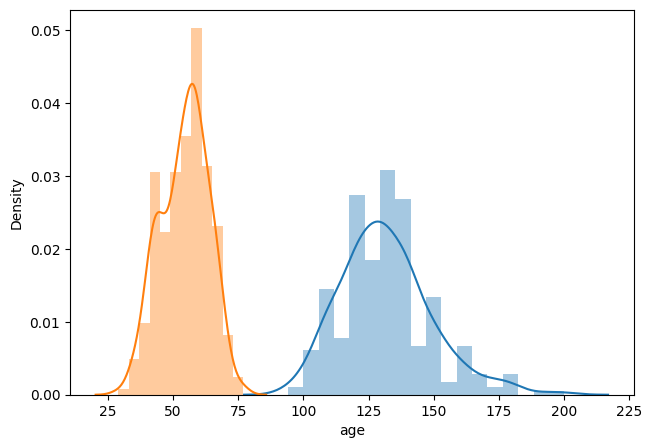

In [4]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['trestbps'])
plt.subplot(1,2,1)
sns.distplot(df['age'])

In [6]:
df['age'].skew()

np.float64(-0.2024633654856539)

<Axes: ylabel='trestbps'>

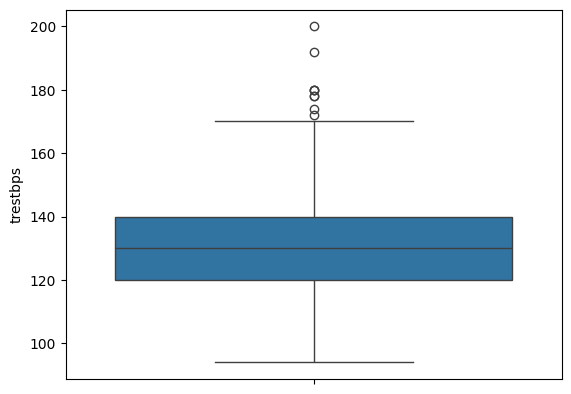

In [9]:
sns.boxplot(df['trestbps'])

In [10]:
#finding th iqr
trestbps25=df['trestbps'].quantile(0.25)
trestbps75=df['trestbps'].quantile(0.75)

In [12]:
iqr=trestbps75-trestbps25

In [13]:
upper_limit=trestbps75+1.5*iqr
lower_limit=trestbps25-1.5*iqr

In [14]:
df[df['trestbps']>upper_limit]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
101,59,1,3,178,270,0,0,145,0,4.2,0,0,3,1
110,64,0,0,180,325,0,1,154,1,0.0,2,0,2,1
203,68,1,2,180,274,1,0,150,1,1.6,1,0,3,0
223,56,0,0,200,288,1,0,133,1,4.0,0,2,3,0
241,59,0,0,174,249,0,1,143,1,0.0,1,0,2,0
248,54,1,1,192,283,0,0,195,0,0.0,2,1,3,0
260,66,0,0,178,228,1,1,165,1,1.0,1,2,3,0
266,55,0,0,180,327,0,2,117,1,3.4,1,0,2,0


In [15]:
df[df['trestbps']<lower_limit]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target


In [17]:
#trimming
new_df=df[df['trestbps']<upper_limit]

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14828\1681200808.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['trestbps'])
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14828\1681200808.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df['trestbps'])


<Axes: ylabel='trestbps'>

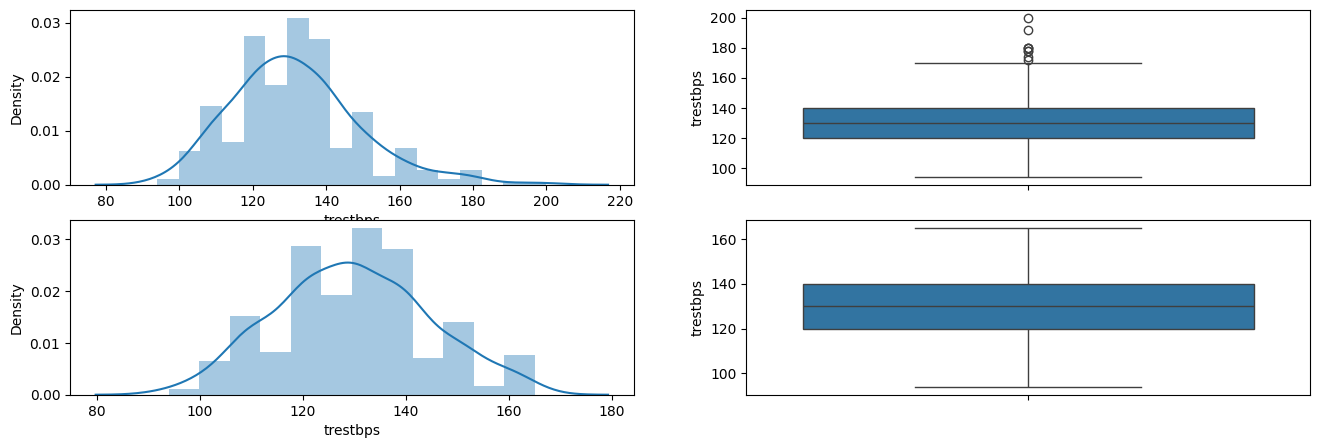

In [20]:
#comparing
plt.figure(figsize=(16,5))
plt.subplot(2,2,1)
sns.distplot(df['trestbps'])
plt.subplot(2,2,2)
sns.boxplot(df['trestbps'])
plt.subplot(2,2,3)
sns.distplot(new_df['trestbps'])
plt.subplot(2,2,4)
sns.boxplot(new_df['trestbps'])

In [21]:
new_df_cap=df.copy()
new_df_cap['trestbps']=np.where(
    new_df_cap['trestbps']>upper_limit,
    upper_limit,
    np.where(
        new_df_cap['trestbps']<lower_limit,
        lower_limit,
        new_df_cap['trestbps']
    )
)